# LM5 Lab — Integration

Companion notebook to **From Calculus to Kelly, LM5**. It rebuilds the module's exhibits and computational examples from verified price files and solves the computational practice problems. Each part ends with `check(...)` lines that compare a computed value with the number printed in the module, at the printed precision, and stop the notebook if they differ (115 checks).

| Part | Rebuilds |
|:--|:--|
| 1 | 0050 total returns (dividends, 4-for-1 split, trading days common with 00631L), verified against FinMind's `spread`; robustness on all 2,906 trading days of 0050 |
| 2 | Left, right and midpoint Riemann sums for a rising deposit rate and their error orders (Example 1, Exhibit 2) |
| 3 | Fundamental theorem, substitution and parts: tail sensitivity to σ, the centre band, LM2's forward curve integrated with SymPy (Examples 2–4) |
| 4 | The Gaussian integral, truncated Pareto moments, 0050's unstable sample kurtosis (Example 5, Exhibit 4) |
| 5 | Monthly rent as right, left and midpoint Riemann sums of a continuous stream; duration; the compounding-convention pitfall (Example 6) |
| 6 | The nine −5% days, thresholds against the normal model and an illustrative Student-t, Mills bounds, tail means, the lognormal mean (Exhibit 1, Exhibit 6, Exhibit 7, Examples 7–9) |
| 7 | Trapezoid and Simpson errors and ratios, Richardson extrapolation, the whole-line trapezoid rule, `scipy.integrate.quad` (Example 10, Exhibit 8) |
| 8 | Computational practice problems (1, 2, 4, 5, 7, 8, 9, 10, 11, 13, 14, 15, 16) and an extension on volatility clustering |

**Data.** The notebook reads FinMind files that you download once with your own token. From the repository root, run `uv run python data/fetch_finmind.py`, then `uv run python data/make_lab_data.py`. FinMind's licence does not allow the book to redistribute the data. After that, the notebook runs offline. The files are FinMind `TaiwanStockPrice` closes for 0050 and 00631L (2014-10-31 → 2026-10-08) and 0050's cash dividends from `TaiwanStockDividendResult`, retrieved 2026-10-10. Part 1 checks every close against FinMind's own `spread` column (close − previous close); the only mismatches are ex-dividend and split days, which it handles explicitly.

**Environment.** From the repository root, `uv sync` installs the locked Python environment (`uv.lock`). Open this notebook with the `.venv` kernel, or run `uv run --with jupyterlab jupyter lab`.

In [1]:
from pathlib import Path
import math
import numpy as np
import polars as pl
import matplotlib.pyplot as plt
from scipy import integrate, special, stats

DATA = Path("data")
pl.Config.set_tbl_rows(30)
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

def check(label, value, printed, fmt):
    # Stop if `value`, formatted with `fmt`, differs from the string printed in the module.
    got = format(value, fmt)
    assert got == printed, f"{label}: computed {got}, module prints {printed}"
    print(f"ok  {label:<44s} {got}")

Phi = lambda z: 0.5 * special.erfc(-z / math.sqrt(2.0))      # accurate far into the tail
phi = lambda z: np.exp(-0.5 * np.asarray(z) ** 2) / math.sqrt(2 * math.pi)

## Part 1 — Total-return series, corporate actions, verification

On an ex-dividend date the total return is $R_t=(P_t+D_t)/P_{t-1}-1$. 0050 split 4-for-1 effective **2025-06-18** and 00631L 22-for-1 effective **2026-03-31**; on a split day the previous close is first divided by the split ratio. As in LM3 and LM4, the book's standard series uses the trading days common to both funds, which gives 2,902 daily returns.

In [2]:
SPLITS = {"0050": ("2025-06-18", 4), "00631L": ("2026-03-31", 22)}
div = pl.read_csv(DATA / "0050_dividends.csv")

def load_raw(sym):
    df = pl.read_csv(DATA / f"{sym}_daily_raw.csv").sort("date")
    gap = (pl.col("close") - pl.col("close").shift(1) - pl.col("spread")).abs()
    bad = df.with_columns(gap.alias("gap")).filter(pl.col("gap") > 0.005)
    expected = (set(div["date"].to_list()) if sym == "0050" else set()) | {SPLITS[sym][0]}
    unexplained = set(bad["date"].to_list()) - expected
    print(f"{sym}: {df.height} closes, checksum mismatches {bad.height}, unexplained {sorted(unexplained)}")
    assert not unexplained
    return df

def with_actions(sym):
    df = load_raw(sym)
    sd, ratio = SPLITS[sym]
    d = div.select("date", pl.col("cash_dividend").alias("D")) if sym == "0050" else \
        pl.DataFrame({"date": [], "D": []}, schema={"date": pl.Utf8, "D": pl.Float64})
    return (df.join(d, on="date", how="left")
              .with_columns(pl.col("D").fill_null(0.0),
                            pl.when(pl.col("date") == pl.lit(sd)).then(ratio).otherwise(1).cast(pl.Float64).alias("split"))
              .select("date", pl.col("close").alias(f"P_{sym}"), pl.col("D").alias(f"D_{sym}"), pl.col("split").alias(f"S_{sym}")))

both = with_actions("0050").join(with_actions("00631L"), on="date", how="inner").sort("date")
ret = (both.with_columns(((pl.col("P_0050") + pl.col("D_0050")) / (pl.col("P_0050").shift(1) / pl.col("S_0050")) - 1).alias("R"))
           .drop_nulls("R").select("date", "R"))
R = ret["R"].to_numpy(); dates = ret["date"].to_list(); n = len(R)
years = (np.datetime64(dates[-1]) - np.datetime64("2014-10-31")).astype(int) / 365.25
A = n / years                                      # returns per year in this sample (the book's A)
mu, s = R.mean(), R.std()                          # population standard deviation, as in the module
print(n, dates[0], "->", dates[-1], f"years={years:.2f}  A={A:.1f}")
check("number of daily returns", n, "2902", "d")
check("mean daily return (%)", mu * 100, "0.0871", ".4f")
check("population sd (%)", s * 100, "1.2385", ".4f")
check("T-1 sd (%)", R.std(ddof=1) * 100, "1.23873", ".5f")
check("trading days per year A", A, "243.1", ".1f")

0050: 2907 closes, checksum mismatches 23, unexplained []
00631L: 2908 closes, checksum mismatches 1, unexplained []
2902 2014-11-03 -> 2026-10-08 years=11.94  A=243.1
ok  number of daily returns                      2902
ok  mean daily return (%)                        0.0871
ok  population sd (%)                            1.2385
ok  T-1 sd (%)                                   1.23873
ok  trading days per year A                      243.1


In [3]:
# Robustness: all 2,906 trading days of 0050 on their own. 00631L did not trade from 25 to 30 March 2026
# (its split), so the common-day series merges 0050's five sessions of 25-31 March into one return.
only = (with_actions("0050")
        .with_columns(((pl.col("P_0050") + pl.col("D_0050")) / (pl.col("P_0050").shift(1) / pl.col("S_0050")) - 1).alias("R"))
        .drop_nulls("R"))
Ro = only["R"].to_numpy()
print("0050 sessions missing from the common days:", sorted(set(only["date"].to_list()) - set(dates)))
check("common-day return 24 -> 31 March 2026 (%)", R[dates.index("2026-03-31")] * 100, "-2.755", ".3f")
for kappa in (-0.02, -0.03, -0.04, -0.05, -0.06, -0.07, -0.08, -0.09, -0.10):
    assert (Ro <= kappa + 1e-12).sum() == (R <= kappa + 1e-12).sum()
print(len(Ro), "returns; every threshold count of Exhibit 6 is unchanged")

# Bands lo < R <= hi of Example 3, with the same 1e-12 guard as the thresholds: prices have two
# decimals, so returns of exactly -1% or +1% are ties that float division can push to either side of the edge.
def band(x, lo, hi):
    return int(((x > lo + 1e-12) & (x <= hi + 1e-12)).sum())

BANDS = ((-0.03, -0.01), (-0.01, 0.01), (0.01, 0.03))
moves = [band(Ro, lo, hi) - band(R, lo, hi) for lo, hi in BANDS]
print("band counts, common days:", [band(R, lo, hi) for lo, hi in BANDS],
      " all 0050 days:", [band(Ro, lo, hi) for lo, hi in BANDS])
check("band counts move by one or two days", f"{min(moves)} to {max(moves)}", "1 to 2", "s")

0050: 2907 closes, checksum mismatches 23, unexplained []
0050 sessions missing from the common days: ['2026-03-25', '2026-03-26', '2026-03-27', '2026-03-30']
ok  common-day return 24 -> 31 March 2026 (%)    -2.755
2906 returns; every threshold count of Exhibit 6 is unchanged
band counts, common days: [352, 2029, 434]  all 0050 days: [354, 2030, 435]
ok  band counts move by one or two days          1 to 2


## Part 2 — Riemann sums and their error orders (Example 1, Exhibit 2)

$r(t)=2.0\%-0.5\%\,e^{-2t}$ on $[0,1]$. The exact integral, from Section 3, is $2.0\%+0.25\%\,(e^{-2}-1)$.

In [4]:
r_t = lambda t: 0.02 - 0.005 * np.exp(-2 * np.asarray(t, dtype=float))
I1 = 0.02 + 0.0025 * (math.exp(-2) - 1)

def riemann(f, a, b, N):
    dt = (b - a) / N; t = a + dt * np.arange(N)
    return dt * f(t).sum(), dt * f(t + dt).sum(), dt * f(t + dt / 2).sum()

rows = []
for N in (4, 12, 365):
    L, Rr, M = riemann(r_t, 0, 1, N)
    rows.append({"N": N, "left_%": L * 100, "right_%": Rr * 100, "mid_%": M * 100,
                 "left_err_bp": (L - I1) * 1e4, "right_err_bp": (Rr - I1) * 1e4, "mid_err_bp": (M - I1) * 1e4})
tab = pl.DataFrame(rows)
print(tab)
check("exact accumulated rate (%)", I1 * 100, "1.783834", ".6f")
check("L4 (%)", rows[0]["left_%"], "1.7253", ".4f")
check("R4 (%)", rows[0]["right_%"], "1.8334", ".4f")
check("M4 error (bp)", rows[0]["mid_err_bp"], "0.224", ".3f")
check("M12 error (bp)", rows[1]["mid_err_bp"], "0.0250", ".4f")
check("L365 error (bp)", rows[2]["left_err_bp"], "-0.0593", ".4f")
check("NT$ exact", 1e6 * math.exp(I1), "1,017,998", ",.0f")
check("NT$ quarterly left", 1e6 * math.exp(rows[0]["left_%"] / 100), "1,017,403", ",.0f")
check("NT$ quarterly midpoint", 1e6 * math.exp(rows[0]["mid_%"] / 100), "1,018,021", ",.0f")

shape: (3, 7)
┌─────┬──────────┬──────────┬──────────┬─────────────┬──────────────┬────────────┐
│ N   ┆ left_%   ┆ right_%  ┆ mid_%    ┆ left_err_bp ┆ right_err_bp ┆ mid_err_bp │
│ --- ┆ ---      ┆ ---      ┆ ---      ┆ ---         ┆ ---          ┆ ---        │
│ i64 ┆ f64      ┆ f64      ┆ f64      ┆ f64         ┆ f64          ┆ f64        │
╞═════╪══════════╪══════════╪══════════╪═════════════╪══════════════╪════════════╡
│ 4   ┆ 1.725307 ┆ 1.833391 ┆ 1.786069 ┆ -5.852635   ┆ 4.955674     ┆ 0.223542   │
│ 12  ┆ 1.76532  ┆ 1.801348 ┆ 1.784084 ┆ -1.8514     ┆ 1.75137      ┆ 0.024999   │
│ 365 ┆ 1.783241 ┆ 1.784426 ┆ 1.783834 ┆ -0.059278   ┆ 0.05917      ┆ 0.000027   │
└─────┴──────────┴──────────┴──────────┴─────────────┴──────────────┴────────────┘
ok  exact accumulated rate (%)                   1.783834
ok  L4 (%)                                       1.7253
ok  R4 (%)                                       1.8334
ok  M4 error (bp)                                0.224
ok  M12 error 

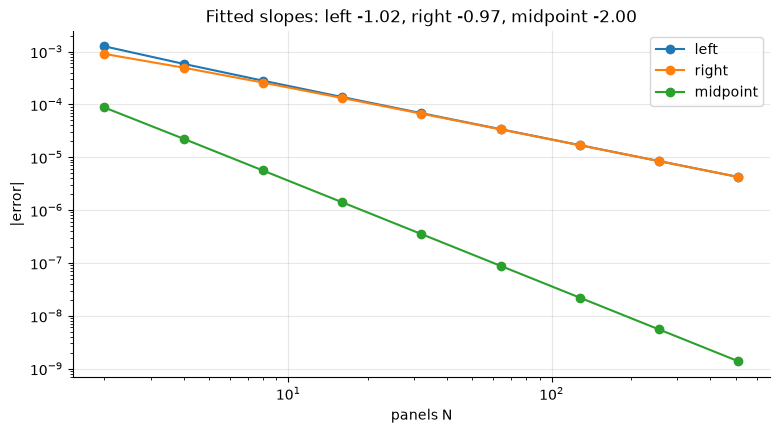

In [5]:
# Error against N on a log-log plot: slope -1 for left/right sums, -2 for midpoint sums
Ns = np.array([2, 4, 8, 16, 32, 64, 128, 256, 512])
errs = np.array([[abs(v - I1) for v in riemann(r_t, 0, 1, int(k))] for k in Ns])
fig, ax = plt.subplots()
for j, lab in enumerate(["left", "right", "midpoint"]):
    ax.loglog(Ns, errs[:, j], "o-", label=lab)
slope = np.polyfit(np.log(Ns), np.log(errs), 1)[0]
ax.set_xlabel("panels N"); ax.set_ylabel("|error|"); ax.legend()
ax.set_title(f"Fitted slopes: left {slope[0]:.2f}, right {slope[1]:.2f}, midpoint {slope[2]:.2f}")
plt.show()

## Part 3 — Fundamental theorem, substitution, parts (Examples 2–4)

In [6]:
kappa, z5 = -0.05, (-0.05 - mu) / s
p5 = Phi(z5)
# Example 2: elasticity of Phi((kappa - mu)/sigma) with respect to sigma
lam = phi(z5) / p5
el = -z5 * lam
z10 = z5 / 1.1
p10 = Phi(z10)
check("z for -5%", z5, "-4.1074386", ".7f")
check("phi(z) x 1e5", float(phi(z5)) * 1e5, "8.6578", ".4f")
check("phi(z)/Phi(z)", lam, "4.328", ".3f")
check("elasticity", el, "17.78", ".2f")
check("z with sigma +10%", z10, "-3.73404", ".5f")
check("Phi with sigma +10% x 1e5", p10 * 1e5, "9.422", ".3f")
check("ratio after +10%", p10 / p5, "4.71", ".2f")
check("17.78 ln 1.1", 17.78 * math.log(1.1), "1.6946", ".4f")
check("elasticity at the new z", -z10 * float(phi(z10)) / p10, "14.83", ".2f")
check("expected days after +10%", n * p10, "0.27", ".2f")

# Example 3: the tail with unrounded inputs, the T-1 standard deviation, and the centre band
check("z from the printed inputs", (-0.05 - 0.000871205) / 0.0123851406, "-4.1074386", ".7f")
check("z with the T-1 sd 1.23873%", (-0.05 - 0.000871205) / 0.0123873, "-4.1067", ".4f")
check("T-1 sd: probability higher by (%)", (Phi((-0.05 - mu) / R.std(ddof=1)) / p5 - 1) * 100, "0.3", ".1f")
zu, zd = (0.01 - mu) / s, (-0.01 - mu) / s
check("z_up", zu, "0.737", ".3f")
check("z_dn", zd, "-0.878", ".3f")
check("Phi(0.737)", Phi(zu), "0.769", ".3f")
check("Phi(-0.878)", Phi(zd), "0.190", ".3f")
check("normal Pr(-1% < R <= 1%)", Phi(zu) - Phi(zd), "0.579", ".3f")
check("actual days, -1% < R <= 1%", band(R, -0.01, 0.01), "2,029", ",d")
check("data share in the band (%)", band(R, -0.01, 0.01) / n * 100, "69.92", ".2f")
z3m, z3p = (-0.03 - mu) / s, (0.03 - mu) / s
check("normal days, -3% < R <= -1%", n * (Phi(zd) - Phi(z3m)), "533", ".0f")
check("actual days, -3% < R <= -1%", band(R, -0.03, -0.01), "352", "d")
check("normal days, 1% < R <= 3%", n * (Phi(z3p) - Phi(zu)), "642", ".0f")
check("actual days, 1% < R <= 3%", band(R, 0.01, 0.03), "434", "d")
# Knowledge check: the upper tail at +5%
check("Pr(R > 5%) x 1e5", Phi(-(0.05 - mu) / s) * 1e5, "3.64", ".2f")
check("expected days above +5%", n * Phi(-(0.05 - mu) / s), "0.106", ".3f")

ok  z for -5%                                    -4.1074386
ok  phi(z) x 1e5                                 8.6578
ok  phi(z)/Phi(z)                                4.328
ok  elasticity                                   17.78
ok  z with sigma +10%                            -3.73404
ok  Phi with sigma +10% x 1e5                    9.422
ok  ratio after +10%                             4.71
ok  17.78 ln 1.1                                 1.6946
ok  elasticity at the new z                      14.83
ok  expected days after +10%                     0.27
ok  z from the printed inputs                    -4.1074386
ok  z with the T-1 sd 1.23873%                   -4.1067
ok  T-1 sd: probability higher by (%)            0.3
ok  z_up                                         0.737
ok  z_dn                                         -0.878
ok  Phi(0.737)                                   0.769
ok  Phi(-0.878)                                  0.190
ok  normal Pr(-1% < R <= 1%)                     0.

In [7]:
# Example 4: integrate LM2's forward curve r(t) = 2% - 0.8% e^{-t/3} (1 - t/3) back into T*y(T)
import sympy as sp
t, T = sp.symbols("t T", positive=True)
r_fwd = sp.Rational(2, 100) - sp.Rational(8, 1000) * sp.exp(-t / 3) * (1 - t / 3)
acc = sp.simplify(sp.integrate(r_fwd, (t, 0, T)))
print("integral of r from 0 to T =", acc)          # T*(1/50 - exp(-T/3)/125), i.e. T*y(T)
for TT in (1, 5, 10):
    val = float(acc.subs(T, TT))
    num = integrate.quad(lambda x: 0.02 - 0.008 * math.exp(-x / 3) * (1 - x / 3), 0, TT)[0]
    print(TT, f"{val:.7f}  quad {num:.7f}  y(T) {val / TT:.5%}  P(T) {math.exp(-val):.6f}")
check("P(10)", math.exp(-float(acc.subs(T, 10))), "0.821071", ".6f")
check("t e^{-t/3} integral, T=5", float(sp.integrate(t * sp.exp(-t / 3), (t, 0, 5))), "4.466986", ".6f")

integral of r from 0 to T = T/50 - T*exp(-T/3)/125
1 0.0142677  quad 0.0142677  y(T) 1.42677%  P(T) 0.985834
5 0.0924450  quad 0.0924450  y(T) 1.84890%  P(T) 0.911699
10 0.1971461  quad 0.1971461  y(T) 1.97146%  P(T) 0.821071
ok  P(10)                                        0.821071
ok  t e^{-t/3} integral, T=5                     4.466986


## Part 4 — Improper integrals, the Gaussian integral, power tails (Example 5, Exhibit 4)

In [8]:
val, err = integrate.quad(lambda x: math.exp(-0.5 * x * x), -np.inf, np.inf)
print(f"Gaussian integral {val:.12f}  sqrt(2 pi) {math.sqrt(2 * math.pi):.12f}")
z_ = np.linspace(-12, 12, 200001)
print("variance of phi by trapezoid:", integrate.trapezoid(z_**2 * phi(z_), z_))

# Example 5: Pareto alpha = 3; truncated third and fourth moments diverge
alpha = 3.0
for b in (10, 100, 1000):
    m3 = integrate.quad(lambda x: x**3 * alpha * x ** (-alpha - 1), 1, b)[0]
    m4 = integrate.quad(lambda x: x**4 * alpha * x ** (-alpha - 1), 1, b)[0]
    print(b, f"{m3:.3f}", f"{m4:,.0f}")
check("3 ln 1000", 3 * math.log(1000), "20.723", ".3f")
check("data mean beyond -3% (%)", R[R <= -0.03 + 1e-12].mean() * 100, "-4.42", ".2f")
check("data mean beyond -5% (%)", R[R <= -0.05 + 1e-12].mean() * 100, "-6.54", ".2f")
zu3 = (-0.03 - mu) / s
check("normal tail mean beyond -3% (%)", (mu - s * phi(zu3) / Phi(zu3)) * 100, "-3.40", ".2f")

Gaussian integral 2.506628274631  sqrt(2 pi) 2.506628274631
variance of phi by trapezoid: 1.0
10 6.908 27
100 13.816 297
1000 20.723 2,997
ok  3 ln 1000                                    20.723
ok  data mean beyond -3% (%)                     -4.42
ok  data mean beyond -5% (%)                     -6.54
ok  normal tail mean beyond -3% (%)              -3.40


ok  excess kurtosis, full sample                 8.12
ok  without 2025-04-07                           7.05
ok  without the four largest moves               3.85
ok  eve of 7 April 2025                          5.84
ok  after 7 April 2025                           7.63
ok  top-10 share of sum of 4th powers (%)        62.8
ok  top-10 share of sum of squares (%)           14.1


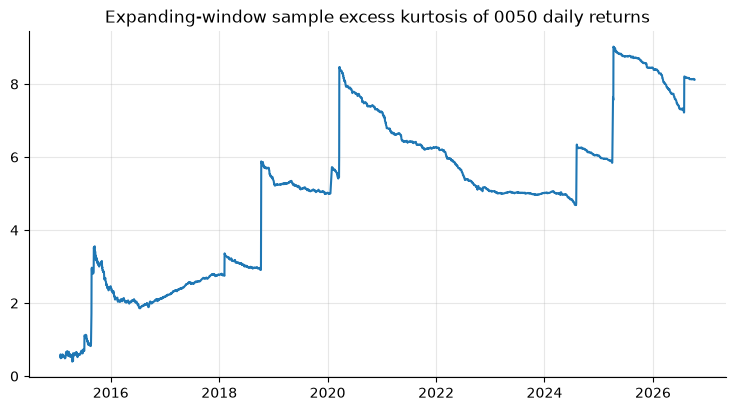

In [9]:
# Pitfall: the sample kurtosis never settles
def exkurt(x):
    return ((x - x.mean()) ** 4).mean() / x.std() ** 4 - 3

check("excess kurtosis, full sample", exkurt(R), "8.12", ".2f")
check("without 2025-04-07", exkurt(ret.filter(pl.col("date") != pl.lit("2025-04-07"))["R"].to_numpy()), "7.05", ".2f")
big4 = ["2025-04-07", "2024-08-05", "2026-07-31", "2025-04-10"]
check("without the four largest moves", exkurt(ret.filter(~pl.col("date").is_in(big4))["R"].to_numpy()), "3.85", ".2f")
pre = np.array([d < "2025-04-07" for d in dates]); upto = np.array([d <= "2025-04-07" for d in dates])
check("eve of 7 April 2025", exkurt(R[pre]), "5.84", ".2f")
check("after 7 April 2025", exkurt(R[upto]), "7.63", ".2f")
dev4 = np.sort((R - mu) ** 4)[::-1]; dev2 = np.sort((R - mu) ** 2)[::-1]
check("top-10 share of sum of 4th powers (%)", dev4[:10].sum() / dev4.sum() * 100, "62.8", ".1f")
check("top-10 share of sum of squares (%)", dev2[:10].sum() / dev2.sum() * 100, "14.1", ".1f")

ek = [exkurt(R[: i + 1]) for i in range(60, n)]
fig, ax = plt.subplots()
ax.plot(np.array(dates[60:], dtype="datetime64[D]"), ek)
ax.set_title("Expanding-window sample excess kurtosis of 0050 daily returns"); plt.show()

## Part 5 — Continuous cash flows (Example 6)

Monthly payments are Riemann sums of $\int_0^T \mathrm{CF}(t)\,e^{-rt}dt$: in arrears = right endpoints, in advance = left endpoints, mid-month = midpoints.

In [10]:
r0, T0, cf = 0.02, 20, 360_000
j = np.arange(1, 241); dt = 1 / 12
factor = (1 - math.exp(-r0 * T0)) / r0
cont = cf * factor
arrears = (30_000 * np.exp(-r0 * j * dt)).sum()
advance = (30_000 * np.exp(-r0 * (j - 1) * dt)).sum()
middle = (30_000 * np.exp(-r0 * (j - 0.5) * dt)).sum()
quadpv = integrate.quad(lambda t: cf * math.exp(-r0 * t), 0, T0)[0]
check("annuity factor", factor, "16.483998", ".6f")
check("continuous stream", cont, "5,934,239", ",.0f")
check("quad", quadpv, "5,934,239", ",.0f")
check("in arrears", arrears, "5,929,295", ",.0f")
check("in advance", advance, "5,939,186", ",.0f")
check("mid-month", middle, "5,934,238", ",.0f")
check("mid-month gap (NT$)", cont - middle, "0.69", ".2f")
check("advance vs arrears (%)", (advance / arrears - 1) * 100, "0.167", ".3f")
D_mac = 1 / r0 - T0 / (math.exp(r0 * T0) - 1)
check("duration of the 20-year stream", D_mac, "9.335", ".3f")
r_eff = math.log1p(0.02)
check("PV with r = ln(1.02)", cf * (1 - math.exp(-r_eff * T0)) / r_eff, "5,945,187", ",.0f")

ok  annuity factor                               16.483998
ok  continuous stream                            5,934,239
ok  quad                                         5,934,239
ok  in arrears                                   5,929,295
ok  in advance                                   5,939,186
ok  mid-month                                    5,934,238
ok  mid-month gap (NT$)                          0.69
ok  advance vs arrears (%)                       0.167
ok  duration of the 20-year stream               9.335
ok  PV with r = ln(1.02)                         5,945,187


## Part 6 — The normal model against 0050's tails (Exhibit 1, Exhibit 6, Exhibit 7, Examples 7–9)

In [11]:
nine = ret.filter(pl.col("R") <= -0.05 + 1e-12).with_columns(((pl.col("R") - mu) / s).alias("z"))
nine = nine.with_columns(pl.Series("P_normal", Phi(nine["z"].to_numpy())))      # no closed form: SciPy at the edge
nine = nine.with_columns((1 / (pl.col("P_normal") * A)).alias("years_between"))
print(nine)                                          # Exhibit 1
check("days at or below -5%", nine.height, "9", "d")
check("normal Pr(R <= -5%) x 1e5", p5 * 1e5, "2.0004", ".4f")
check("expected days", n * p5, "0.0581", ".4f")
check("return period (years)", 1 / (p5 * A), "205.6", ".1f")
check("actual / expected", nine.height / (n * p5), "155", ".0f")
check("mean of the nine (%)", nine["R"].mean() * 100, "-6.54", ".2f")
check("return period, 2018-10-11 row (2 s.f.)", float(nine["years_between"][0]), "8.9e+05", ".1e")
check("return period, 2022-10-11 row (2 s.f.)", float(nine["years_between"][3]), "3.9e+02", ".1e")
# z in Exhibit 1 comes from the unrounded return, mu_hat and s, as its note says
check("z, 2024-04-19 row", float(nine["z"][4]), "-4.160", ".3f")
check("z, summary row", z5, "-4.1074", ".4f")

shape: (9, 5)
┌────────────┬───────────┬───────────┬────────────┬───────────────┐
│ date       ┆ R         ┆ z         ┆ P_normal   ┆ years_between │
│ ---        ┆ ---       ┆ ---       ┆ ---        ┆ ---           │
│ str        ┆ f64       ┆ f64       ┆ f64        ┆ f64           │
╞════════════╪═══════════╪═══════════╪════════════╪═══════════════╡
│ 2018-10-11 ┆ -0.07027  ┆ -5.744099 ┆ 4.6206e-9  ┆ 890229.718101 │
│ 2020-01-30 ┆ -0.056807 ┆ -4.657013 ┆ 0.000002   ┆ 2564.204728   │
│ 2020-03-19 ┆ -0.058379 ┆ -4.783985 ┆ 8.5927e-7  ┆ 4787.074775   │
│ 2022-10-11 ┆ -0.051789 ┆ -4.251892 ┆ 0.000011   ┆ 388.10608     │
│ 2024-04-19 ┆ -0.050645 ┆ -4.159506 ┆ 0.000016   ┆ 257.942946    │
│ 2024-08-02 ┆ -0.050543 ┆ -4.15132  ┆ 0.000017   ┆ 248.871133    │
│ 2024-08-05 ┆ -0.091299 ┆ -7.442029 ┆ 4.9575e-14 ┆ 8.2972e10     │
│ 2025-04-07 ┆ -0.1      ┆ -8.144534 ┆ 1.9037e-16 ┆ 2.1607e13     │
│ 2026-07-17 ┆ -0.058741 ┆ -4.813172 ┆ 7.4277e-7  ┆ 5537.904446   │
└────────────┴───────────┴────────

shape: (9, 7)
┌───────┬───────────┬────────────┬─────────────────┬────────┬─────────────┬───────────────┐
│ kappa ┆ z         ┆ P_normal   ┆ expected_normal ┆ actual ┆ expected_t3 ┆ ratio         │
│ ---   ┆ ---       ┆ ---        ┆ ---             ┆ ---    ┆ ---         ┆ ---           │
│ f64   ┆ f64       ┆ f64        ┆ f64             ┆ i64    ┆ f64         ┆ f64           │
╞═══════╪═══════════╪════════════╪═════════════════╪════════╪═════════════╪═══════════════╡
│ -0.02 ┆ -1.685181 ┆ 0.045977   ┆ 133.42473       ┆ 104    ┆ 89.316246   ┆ 0.779466      │
│ -0.03 ┆ -2.4926   ┆ 0.006341   ┆ 18.400352       ┆ 37     ┆ 33.219178   ┆ 2.010831      │
│ -0.04 ┆ -3.300019 ┆ 0.000483   ┆ 1.4028          ┆ 18     ┆ 15.417267   ┆ 12.831483     │
│ -0.05 ┆ -4.107439 ┆ 0.00002    ┆ 0.05805         ┆ 9      ┆ 8.292473    ┆ 155.037928    │
│ -0.06 ┆ -4.914858 ┆ 4.4423e-7  ┆ 0.001289        ┆ 3      ┆ 4.940363    ┆ 2327.080544   │
│ -0.07 ┆ -5.722277 ┆ 5.2553e-9  ┆ 0.000015        ┆ 3      ┆ 3.16

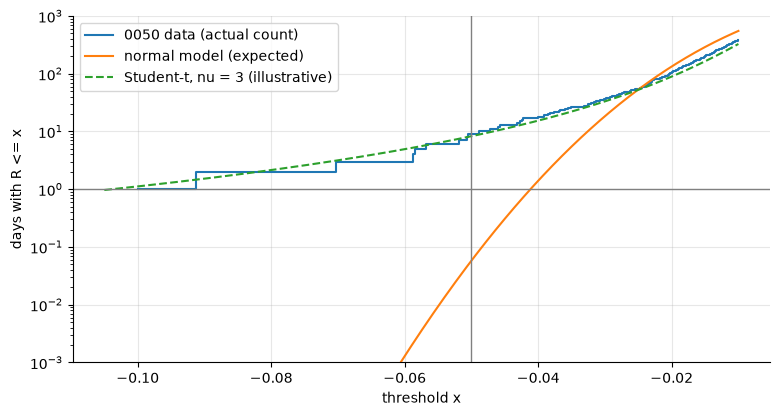

In [12]:
# Exhibit 6: thresholds, normal vs data vs an illustrative Student-t with nu = 3 and the same sd
nu = 3; sc = s * math.sqrt((nu - 2) / nu)
thr = pl.DataFrame({"kappa": [-0.02, -0.03, -0.04, -0.05, -0.06, -0.07, -0.08, -0.09, -0.10]})
kk = thr["kappa"].to_numpy()
thr = thr.with_columns(
    pl.Series("z", (kk - mu) / s),
    pl.Series("P_normal", Phi((kk - mu) / s)),
    pl.Series("expected_normal", n * Phi((kk - mu) / s)),
    pl.Series("actual", [int((R <= k + 1e-12).sum()) for k in kk]),
    pl.Series("expected_t3", n * stats.t.cdf((kk - mu) / sc, nu)),
).with_columns((pl.col("actual") / pl.col("expected_normal")).alias("ratio"))
print(thr)
check("t3 expected at -5%", thr["expected_t3"][3], "8.3", ".1f")
check("normal expected at -2%", thr["expected_normal"][0], "133.4", ".1f")
check("normal Pr at -3% (2 s.f.)", thr["P_normal"][1], "6.3e-03", ".1e")
check("normal Pr at -8% (2 s.f.)", thr["P_normal"][6], "3.3e-11", ".1e")

# Exhibit 7: counts on a log axis
x = np.linspace(-0.105, -0.01, 400)
fig, ax = plt.subplots()
srt = np.sort(R); cnt = np.arange(1, n + 1)
ax.step(srt[srt <= -0.01], cnt[srt <= -0.01], where="post", label="0050 data (actual count)")
ax.plot(x, n * Phi((x - mu) / s), label="normal model (expected)")
ax.plot(x, n * stats.t.cdf((x - mu) / sc, nu), "--", label="Student-t, nu = 3 (illustrative)")
ax.set_yscale("log"); ax.set_ylim(1e-3, 1e3); ax.axvline(-0.05, color="grey", lw=1); ax.axhline(1, color="grey", lw=1)
ax.set_xlabel("threshold x"); ax.set_ylabel("days with R <= x"); ax.legend(); plt.show()

In [13]:
# Example 7: Mills-ratio bracket (5.10) at omega = -z, and Gordon's sharper lower bound
omega = -z5; ph = float(phi(omega))
check("phi(omega) x 1e5", ph * 1e5, "8.6578", ".4f")
check("upper bound x 1e5", ph / omega * 1e5, "2.1078", ".4f")
check("1 - 1/omega^2", 1 - 1 / omega**2, "0.94073", ".5f")
check("lower bound x 1e5", ph / omega * (1 - 1 / omega**2) * 1e5, "1.9829", ".4f")
print(f"Gordon lower bound {ph / (omega + 1 / omega):.4e}; exact {p5:.4e}")
# Example 8: conditional tail mean (5.11)
check("omega + 1/omega", omega + 1 / omega, "4.3509", ".4f")
check("normal E[R | R <= -5%] (%)", (mu - s * lam) * 100, "-5.27", ".2f")
# Example 9: lognormal mean (5.12); the daily log-return moments are annualized with the printed A = 243.1
rl = np.log1p(R); mu_X, var_X = rl.mean() * 243.1, rl.var() * 243.1
check("mu_X", mu_X, "0.19308", ".5f")
check("mu_X (%)", mu_X * 100, "19.31", ".2f")
check("sigma_X (%)", math.sqrt(var_X) * 100, "19.30", ".2f")
check("sigma_X^2", var_X, "0.037265", ".6f")
check("sigma_X^2 / 2", var_X / 2, "0.018632", ".6f")
check("median growth (%)", (math.exp(mu_X) - 1) * 100, "21.30", ".2f")
check("mean growth (%)", (math.exp(mu_X + var_X / 2) - 1) * 100, "23.58", ".2f")
check("realized compound growth (%)", (np.prod(1 + R) ** (1 / years) - 1) * 100, "21.30", ".2f")
check("mean minus median (points)", (math.exp(mu_X + var_X / 2) - math.exp(mu_X)) * 100, "2.28", ".2f")
EG = integrate.quad(lambda x: math.exp(x - 0.5 * (x - mu_X) ** 2 / var_X) / math.sqrt(2 * math.pi * var_X), -np.inf, np.inf)[0]
print(f"E[G] by quadrature {EG:.6f}")

ok  phi(omega) x 1e5                             8.6578
ok  upper bound x 1e5                            2.1078
ok  1 - 1/omega^2                                0.94073
ok  lower bound x 1e5                            1.9829
Gordon lower bound 1.9899e-05; exact 2.0004e-05
ok  omega + 1/omega                              4.3509
ok  normal E[R | R <= -5%] (%)                   -5.27
ok  mu_X                                         0.19308
ok  mu_X (%)                                     19.31
ok  sigma_X (%)                                  19.30
ok  sigma_X^2                                    0.037265
ok  sigma_X^2 / 2                                0.018632
ok  median growth (%)                            21.30
ok  mean growth (%)                              23.58
ok  realized compound growth (%)                 21.30
ok  mean minus median (points)                   2.28
E[G] by quadrature 1.235786


## Part 7 — Numerical integration (Example 10, Exhibit 8)

shape: (8, 6)
┌──────┬──────────┬───────────┬────────────┬────────────┬────────────┐
│ N    ┆ dx       ┆ trap_err  ┆ trap_ratio ┆ simp_err   ┆ simp_ratio │
│ ---  ┆ ---      ┆ ---       ┆ ---        ┆ ---        ┆ ---        │
│ i64  ┆ f64      ┆ f64       ┆ f64        ┆ f64        ┆ f64        │
╞══════╪══════════╪═══════════╪════════════╪════════════╪════════════╡
│ 8    ┆ 0.98657  ┆ 0.000024  ┆ null       ┆ 0.00001    ┆ null       │
│ 16   ┆ 0.493285 ┆ 0.000007  ┆ 3.459871   ┆ 0.000001   ┆ 7.881503   │
│ 32   ┆ 0.246643 ┆ 0.000002  ┆ 3.840265   ┆ 9.4655e-8  ┆ 12.985536  │
│ 64   ┆ 0.123321 ┆ 4.4911e-7 ┆ 3.95838    ┆ 6.2306e-9  ┆ 15.192045  │
│ 128  ┆ 0.061661 ┆ 1.1257e-7 ┆ 3.989488   ┆ 3.9445e-10 ┆ 15.795627  │
│ 256  ┆ 0.03083  ┆ 2.8162e-8 ┆ 3.997365   ┆ 2.4732e-11 ┆ 15.948777  │
│ 512  ┆ 0.015415 ┆ 7.0416e-9 ┆ 3.999341   ┆ 1.5470e-12 ┆ 15.987186  │
│ 1024 ┆ 0.007708 ┆ 1.7605e-9 ┆ 3.999835   ┆ 9.6707e-14 ┆ 15.996802  │
└──────┴──────────┴───────────┴────────────┴────────────┴──────

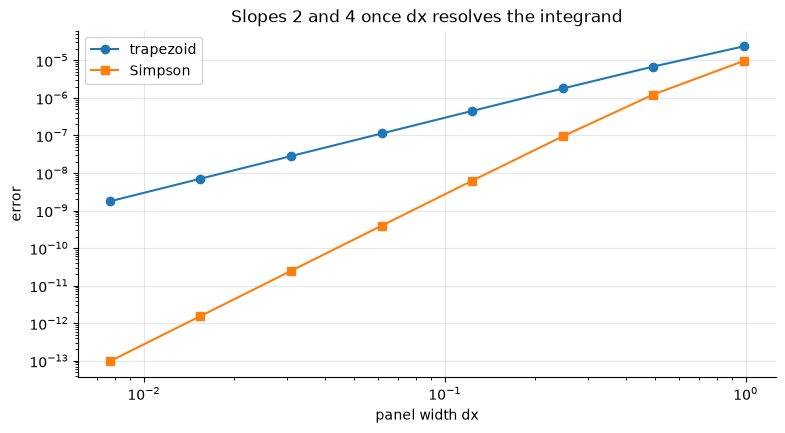

In [14]:
def trapezoid(f, a, b, N):
    x = np.linspace(a, b, N + 1); y = f(x); dx = (b - a) / N
    return dx * (y.sum() - 0.5 * (y[0] + y[-1]))

def simpson(f, a, b, N):
    x = np.linspace(a, b, N + 1); y = f(x); dx = (b - a) / N
    return dx / 3 * (y[0] + y[-1] + 4 * y[1:-1:2].sum() + 2 * y[2:-1:2].sum())

exact = p5 - Phi(-12.0)
rows, prev = [], None
for N in (8, 16, 32, 64, 128, 256, 512, 1024):
    eT, eS = trapezoid(phi, -12, z5, N) - exact, simpson(phi, -12, z5, N) - exact
    rows.append({"N": N, "dx": (z5 + 12) / N, "trap_err": eT, "trap_ratio": None if prev is None else prev[0] / eT,
                 "simp_err": eS, "simp_ratio": None if prev is None else prev[1] / eS})
    prev = (eT, eS)
numint = pl.DataFrame(rows)
print(numint)                                        # Exhibit 8
check("exact value x 1e5", exact * 1e5, "2.000355", ".6f")
check("trapezoid error N=256 x 1e8", rows[5]["trap_err"] * 1e8, "2.82", ".2f")
check("Simpson error N=1024 x 1e14", rows[7]["simp_err"] * 1e14, "9.67", ".2f")
check("trapezoid ratio N=16", rows[1]["trap_ratio"], "3.46", ".2f")
check("Simpson ratio N=1024", rows[7]["simp_ratio"], "16.00", ".2f")
dx256 = rows[5]["dx"]
check("dx at N=256", dx256, "0.03083", ".5f")
check("-z phi(z) x 1e4", -z5 * float(phi(z5)) * 1e4, "3.5561", ".4f")
check("(5.13): T256 - exact predicted x 1e8", dx256**2 / 12 * (-z5 * float(phi(z5))) * 1e8, "2.817", ".3f")
check("T256 - exact observed x 1e8", rows[5]["trap_err"] * 1e8, "2.816", ".3f")
check("Richardson (4T64-T32)/3 x 1e5", (4 * trapezoid(phi, -12, z5, 64) - trapezoid(phi, -12, z5, 32)) / 3 * 1e5, "2.0009784", ".7f")
check("Simpson S64 x 1e5", simpson(phi, -12, z5, 64) * 1e5, "2.0009784", ".7f")

fig, ax = plt.subplots()
ax.loglog(numint["dx"], numint["trap_err"], "o-", label="trapezoid")
ax.loglog(numint["dx"], numint["simp_err"], "s-", label="Simpson")
ax.set_xlabel("panel width dx"); ax.set_ylabel("error"); ax.legend(); ax.set_title("Slopes 2 and 4 once dx resolves the integrand"); plt.show()

In [15]:
# Whole-line trapezoid rule for sqrt(2 pi): far better than O(dx^2), because every endpoint derivative vanishes
for dx in (2.0, 1.5, 1.0, 0.5):
    jj = np.arange(-int(40 / dx), int(40 / dx) + 1)
    print(dx, f"{dx * np.exp(-0.5 * (jj * dx) ** 2).sum() - math.sqrt(2 * math.pi):+.2e}")
check("whole-line error at dx = 1", np.exp(-0.5 * np.arange(-40, 41) ** 2).sum() - math.sqrt(2 * math.pi), "1.3e-08", ".1e")
qv, qe = integrate.quad(lambda t: float(phi(t)), -np.inf, z5)
print("quad:", qv, qe, " relative difference from erfc:", f"{abs(qv - p5) / p5:.1e}")
check("quad value x 1e5", qv * 1e5, "2.000355", ".6f")
check("quad relative difference", abs(qv - p5) / p5 * 1e11, "6.7", ".1f")

2.0 +3.61e-02
1.5 +7.76e-04
1.0 +1.34e-08
0.5 +4.44e-16
ok  whole-line error at dx = 1                   1.3e-08
quad: 2.000355318446267e-05 2.2183600358768839e-10  relative difference from erfc: 6.7e-11
ok  quad value x 1e5                             2.000355
ok  quad relative difference                     6.7


## Part 8 — Practice problems (computational) and an extension

In [16]:
print("PP1 ", f"{(1 - math.exp(-0.3)) / 0.03:.4f}", f"(year-end payments {sum(math.exp(-0.03 * k) for k in range(1, 11)):.4f})")
L4 = 0.25 * np.exp(0.25 * np.arange(4)).sum(); R4 = 0.25 * np.exp(0.25 * np.arange(1, 5)).sum()
print("PP2 ", f"L4={L4:.6f} R4={R4:.6f} exact={math.e - 1:.6f} T4={(L4 + R4) / 2:.6f}",
      f"T4 - exact={(L4 + R4) / 2 - (math.e - 1):+.6f}; (5.13): exact - T4 = {-0.25**2 / 12 * (math.e - 1):+.6f}")
check("PP2 (5.13): exact - T4", -0.25**2 / 12 * (math.e - 1), "-0.008949", ".6f")
print("PP4 ", f"{1 - math.exp(-0.5):.4f}")
print("PP5 ", f"{1 / 0.025:.0f} years")
print("PP7 ", f"E[X]={2.5 / 1.5:.4f} E[X^2]={2.5 / 0.5:.4f} Var={5 - 25 / 9:.4f}")
w8 = (0.06 + 0.0005) / 0.015; ph8 = float(phi(w8)); up8, lo8 = ph8 / w8, ph8 / w8 * (1 - 1 / w8**2)
print("PP8 ", f"z={-w8:.5f} upper={up8:.4e} lower={lo8:.4e} exact={Phi(-w8):.4e} per year={Phi(-w8) * 243.1:.5f} every {1 / (Phi(-w8) * 243.1):.0f} years")
check("PP8 upper bound high by (%)", (up8 / Phi(-w8) - 1) * 100, "5.6", ".1f")
check("PP8 lower bound low by (%)", (1 - lo8 / Phi(-w8)) * 100, "0.9", ".1f")
print("PP9 ", f"{Phi(-4):.4e}  two-sided {2 * Phi(-4):.4e}  Cantelli {1 / 17:.4f}")
print("PP10", f"PV={(1 - math.exp(-0.6)) / 0.02:.4f} forever={1 / 0.02:.1f} share={1 - math.exp(-0.6):.1%}")
g = lambda x: np.exp(-0.5 * x * x); I11 = math.sqrt(2 * math.pi) * (Phi(1) - 0.5)
T2, T4, S4 = trapezoid(g, 0, 1, 2), trapezoid(g, 0, 1, 4), simpson(g, 0, 1, 4)
print("PP11", f"T2={T2:.7f} T4={T4:.7f} S4={S4:.7f} exact={I11:.7f} errors {T2 - I11:+.7f} {T4 - I11:+.7f} {S4 - I11:+.7f}")
check("PP11 S4", S4, "0.8556513", ".7f")
print("PP13", f"mean={math.exp(0.10):.4f} median={math.exp(0.08):.4f} Pr(G<1)={Phi(-0.4):.4f}")
print("PP14", f"{-float(phi(2)) / Phi(-2):.4f}")
up = ret.filter(pl.col("R") >= 0.05 - 1e-12)
print("PP15", up, f"expected {n * Phi(-(0.05 - mu) / s):.3f}")
check("PP15 days at or above +5%", up.height, "6", "d")
z9 = stats.norm.ppf(9 / n); sig9 = (-0.05 - mu) / z9
print("PP16", f"z={z9:.4f}  sigma={sig9:.4%}  at -2%: {n * Phi((-0.02 - mu) / sig9):.0f}  at -3%: {n * Phi((-0.03 - mu) / sig9):.0f}")
check("PP16 z", z9, "-2.7369", ".4f")
check("PP16 sigma (%)", sig9 * 100, "1.8587", ".4f")

PP1  8.6394 (year-end payments 8.5104)
PP2  L4=1.512437 R4=1.942007 exact=1.718282 T4=1.727222 T4 - exact=+0.008940; (5.13): exact - T4 = -0.008949
ok  PP2 (5.13): exact - T4                       -0.008949
PP4  0.3935
PP5  40 years
PP7  E[X]=1.6667 E[X^2]=5.0000 Var=2.2222
PP8  z=-4.03333 upper=2.9023e-05 lower=2.7239e-05 exact=2.7496e-05 per year=0.00668 every 150 years
ok  PP8 upper bound high by (%)                  5.6
ok  PP8 lower bound low by (%)                   0.9
PP9  3.1671e-05  two-sided 6.3342e-05  Cantelli 0.0588
PP10 PV=22.5594 forever=50.0 share=45.1%
PP11 T2=0.8428811 T4=0.8524588 S4=0.8556513 exact=0.8556244 errors -0.0127433 -0.0031656 +0.0000269
ok  PP11 S4                                      0.8556513
PP13 mean=1.1052 median=1.0833 Pr(G<1)=0.3446
PP14 -2.3732
PP15 shape: (6, 2)
┌────────────┬──────────┐
│ date       ┆ R        │
│ ---        ┆ ---      │
│ str        ┆ f64      │
╞════════════╪══════════╡
│ 2020-03-20 ┆ 0.079504 │
│ 2022-11-11 ┆ 0.05314  │
│ 20

### Extension: how much of the fat tail is changing volatility?

Section 7 notes that part of the gap comes from volatility that changes over time (LM26). Standardize each day's return by a volatility estimated only from the previous 60 days, $z_t=(R_t-\hat\mu)/\hat\sigma_{t-1}$, and count the days with $z_t\le-4.107$, the case's threshold in standard-deviation units. If volatility clustering explained everything, the count would be close to the normal model's 0.058. Try other windows (20, 120, 250 days) and an exponentially weighted estimate, and compare the counts with Exhibit 6.

In [17]:
roll = (ret.with_columns(pl.col("R").rolling_std(window_size=60).shift(1).alias("sd60"))
           .drop_nulls("sd60")
           .with_columns(((pl.col("R") - mu) / pl.col("sd60")).alias("z")))
print(roll.height, "days with a trailing 60-day volatility")
print("days with z <= -4.107:", roll.filter(pl.col("z") <= z5).height,
      " normal expectation:", f"{roll.height * Phi(z5):.3f}")
roll.sort("z").head(10)

2842 days with a trailing 60-day volatility
days with z <= -4.107: 8  normal expectation: 0.057


date,R,sd60,z
str,f64,f64,f64
"""2018-10-11""",-0.07027,0.007724,-9.211005
"""2025-04-07""",-0.1,0.013368,-7.545714
"""2020-01-30""",-0.056807,0.007724,-7.467312
"""2018-02-06""",-0.047249,0.007169,-6.712312
"""2024-08-05""",-0.091299,0.016814,-5.481749
"""2022-10-11""",-0.051789,0.012156,-4.331926
"""2024-04-19""",-0.050645,0.012242,-4.208267
"""2015-08-24""",-0.038462,0.009488,-4.145531
"""2020-03-19""",-0.058379,0.014638,-4.047598
